In [3]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ----- ---------------------------------- 1.0/8.4 MB 8.1 MB/s eta 0:00:01
   ---------------- ----------------------- 3.4/8.4 MB 10.4 MB/s eta 0:00:01
   ---------------------------- ----------- 6.0/8.4 MB 10.7 MB/s eta 0:00:01
   -------------------------------------- - 8.1/8.4 MB 10.6 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 10.4 MB/s  0:00:00
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   - -------------------------------------- 1.8/37.4 MB 8.8 MB/s eta 0:00:05
   --- ------------------------------------ 3.4/37.4 MB 8.7 MB/s eta 0:00:04
   ----- ---------------------------------- 5.2/37.4 MB 8.3 MB/s eta 0:00:04
   ------- -------------------------------- 7.1/37.4 MB 8.5 MB/s eta 0:00:04
   -------- ------------------------------- 8.1/37.4 MB 8.4 MB/s eta 0:00:04
   ---------- ----------------------------- 9.7/37.4 MB 7.7 MB/s eta 0:00:04
   ----------- ---


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [5]:
df = pd.read_csv("../data/food-texture.csv")

if "Unnamed: 0" in df.columns:
    df = df.rename(columns={"Unnamed: 0": "Sample_ID"})

df.head()

,Sample_ID,Oil,Density,Crispy,Fracture,Hardness
0,B110,16.5,2955,10,23,97
1,B136,17.7,2660,14,9,139
2,B171,16.2,2870,12,17,143
3,B192,16.7,2920,10,31,95
4,B225,16.3,2975,11,26,143


In [8]:
X = df[["Oil", "Density", "Fracture", "Hardness"]]
y = df["Crispy"]

print(X.shape)
print(y.shape)
print("\nInput features:", X.columns.tolist())
print("Target:", y.name)

(50, 4)
(50,)

Input features: ['Oil', 'Density', 'Fracture', 'Hardness']
Target: Crispy


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 40
Testing samples: 10


In [11]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[ 0.18,-0. ,-0.16, 0.02]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['Oil','Density','Fracture','Hardness']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,22.13
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [12]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual_Crispy": y_test,
    "Predicted_Crispy": y_pred
})
results["Predicted_Crispy"] = results["Predicted_Crispy"].round(2)

results.sort_index()

,Actual_Crispy,Predicted_Crispy
13,12,11.40
17,12,12.25
19,14,14.27
25,12,12.91
26,10,9.94
30,10,9.65
32,7,7.54
39,10,9.75
45,11,10.60
48,13,13.53


In [13]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE  : {mae:.3f}")
print(f"RMSE : {rmse:.3f}")
print(f"R²   : {r2:.3f}")

MAE  : 0.418
RMSE : 0.476
R²   : 0.935


In [14]:
print("Intercept:", round(model.intercept_, 4))
print("\nCoefficients:")
for feature, coefficient in zip(X.columns, model.coef_):
    print(f"{feature}: {coefficient:.6f}")

Intercept: 22.1313

Coefficients:
Oil: 0.183287
Density: -0.004324
Fracture: -0.161921
Hardness: 0.015489


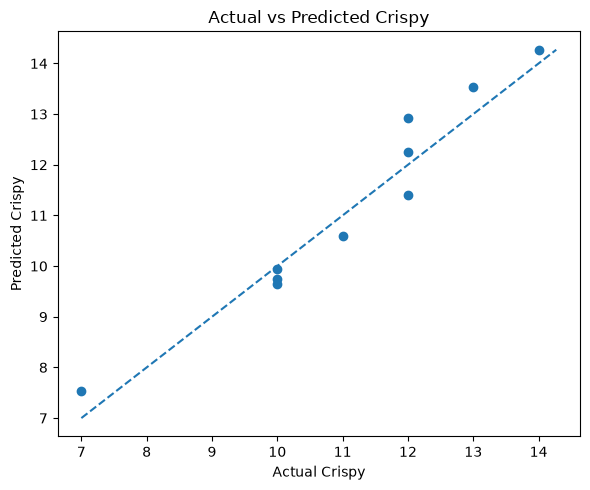

In [15]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred)

low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], linestyle="--")

plt.xlabel("Actual Crispy")
plt.ylabel("Predicted Crispy")
plt.title("Actual vs Predicted Crispy")
plt.tight_layout()
plt.show()